In [ ]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import timm
import numpy as np
from image_preprocess import prepare_datasets 

# Configuration
DATASET_PATH = 'dataset/aerial_landscapes'
NUM_CLASSES = 15
BATCH_SIZE = 1
SEED = 18
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_FILE = "best_model_seresnet50.pth"
TRAIN_ACCS_FILE = "train_accs_seresnet50.npy"
VAL_ACCS_FILE = "val_accs_seresnet50.npy"

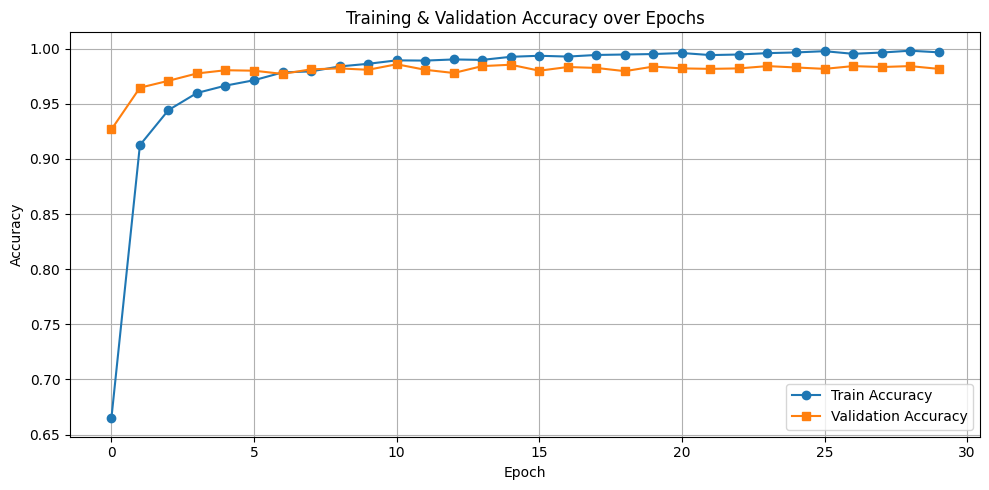

In [2]:
train_accs = np.load(TRAIN_ACCS_FILE)
val_accs = np.load(VAL_ACCS_FILE)

plt.figure(figsize=(10, 5))
plt.plot(train_accs, label="Train Accuracy", marker='o')
plt.plot(val_accs, label="Validation Accuracy", marker='s')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy over Epochs")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
# Set random seed
torch.manual_seed(SEED)

_, test_dataset = prepare_datasets(DATASET_PATH, seed=SEED)
class_names = test_dataset.subset.dataset.classes

def evaluate_model(model_file, test_dataset):
    # Load test set
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    # Load model
    model = timm.create_model('seresnet50', pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(model_file, map_location=DEVICE))
    model.eval().to(DEVICE)

    # Collect predictions
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_preds, all_labels


def plot_confusion_matrix(class_names, all_labels, all_preds, title):
    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 10))
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [4]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
original_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      1.000     0.994     0.997       160
     Airport      0.994     0.988     0.991       160
       Beach      0.982     1.000     0.991       160
        City      0.994     0.994     0.994       160
      Desert      0.981     0.981     0.981       160
      Forest      0.981     0.956     0.968       160
   Grassland      0.964     0.994     0.978       160
     Highway      0.988     0.988     0.988       160
        Lake      0.969     0.988     0.978       160
    Mountain      0.963     0.975     0.969       160
     Parking      0.994     0.994     0.994       160
        Port      1.000     0.994     0.997       160
     Railway      0.994     0.981     0.987       160
 Residential      0.994     1.000     0.997       160
       River      0.994     0.963     0.978       160

    accuracy                          0.986      2400
   macro avg      0.986     0.986     0.986      2400
we

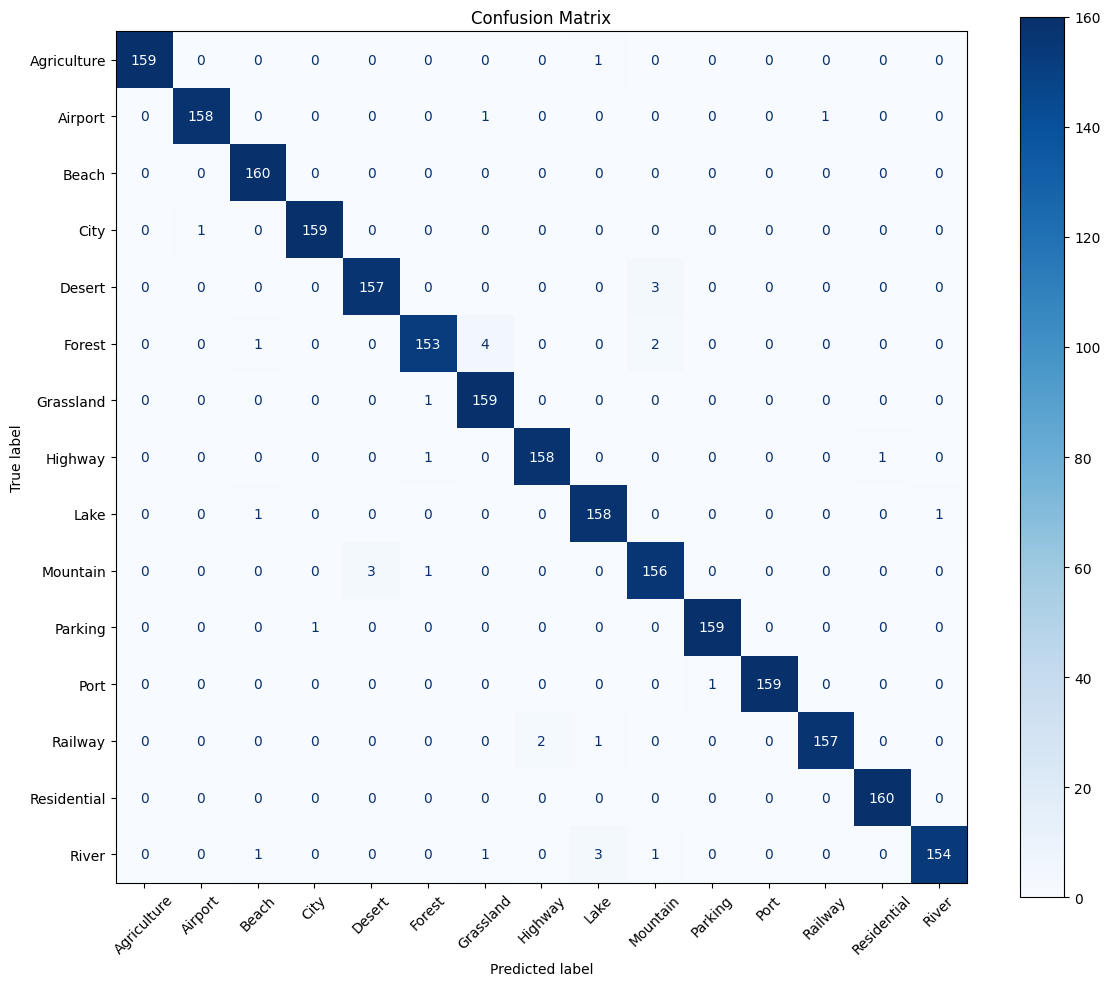

In [5]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [6]:
from image_preprocess import MyDataset
from utils.dataset_utils import get_blur_transform, get_noise_transform, get_patch_transform

raw_test_subset = test_dataset.subset  
test_dataset_patch = MyDataset(raw_test_subset, get_patch_transform())
test_dataset_blur  = MyDataset(raw_test_subset, get_blur_transform())
test_dataset_noise = MyDataset(raw_test_subset, get_noise_transform())

In [7]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_patch)

# Classification Report
print("\nClassification Report:")
patch_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.988     0.988     0.988       160
     Airport      0.969     0.975     0.972       160
       Beach      0.975     0.994     0.985       160
        City      0.975     0.994     0.985       160
      Desert      0.981     0.981     0.981       160
      Forest      0.981     0.950     0.965       160
   Grassland      0.964     0.994     0.978       160
     Highway      0.981     0.988     0.984       160
        Lake      0.919     0.994     0.955       160
    Mountain      0.975     0.963     0.969       160
     Parking      0.994     0.963     0.978       160
        Port      0.994     0.988     0.991       160
     Railway      1.000     0.963     0.981       160
 Residential      0.994     1.000     0.997       160
       River      0.987     0.938     0.962       160

    accuracy                          0.978      2400
   macro avg      0.978     0.978     0.978      2400
we

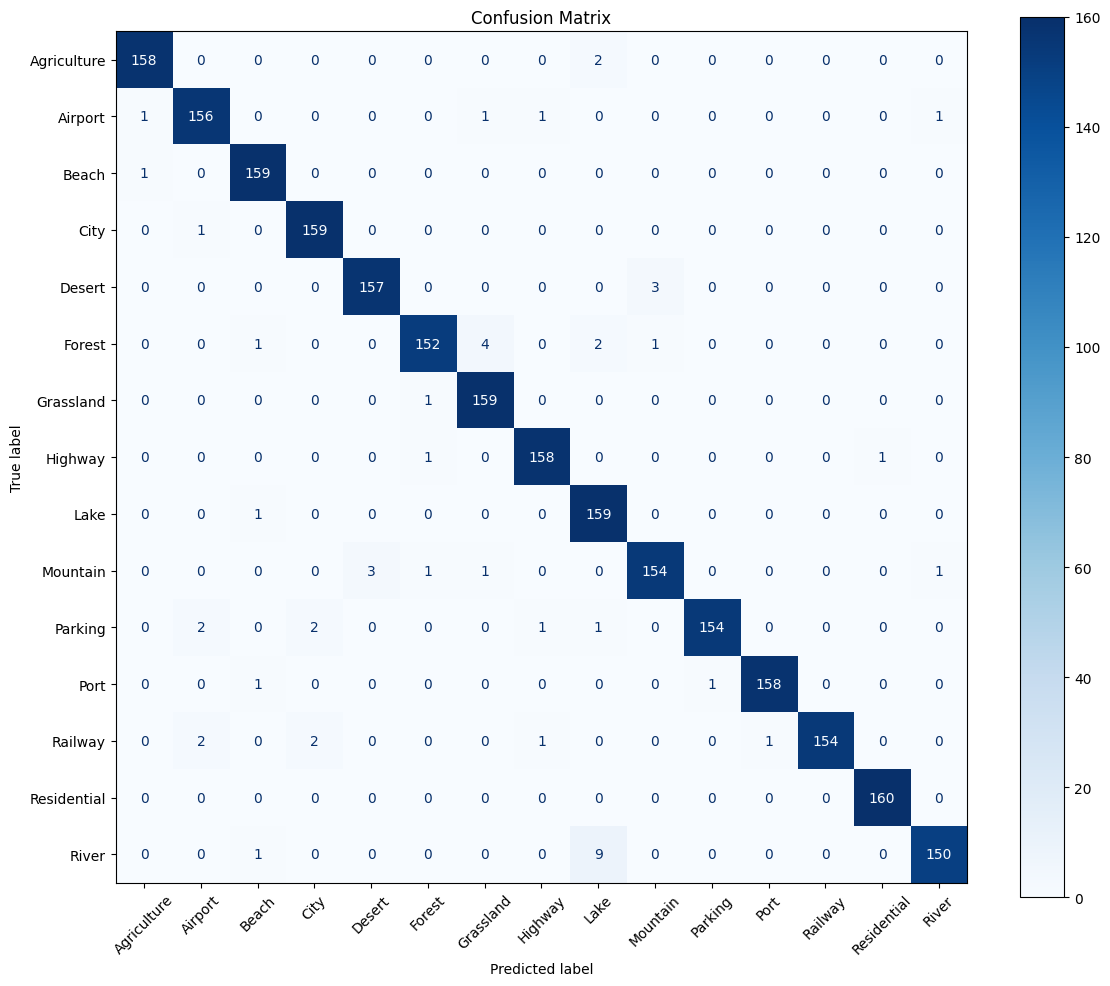

In [8]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [9]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_blur)

# Classification Report
print("\nClassification Report:")
blur_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.941     0.894     0.917       160
     Airport      0.927     0.794     0.855       160
       Beach      0.704     0.981     0.820       160
        City      0.856     0.856     0.856       160
      Desert      0.766     0.981     0.860       160
      Forest      0.929     0.900     0.914       160
   Grassland      0.871     0.800     0.834       160
     Highway      0.960     0.906     0.932       160
        Lake      0.897     0.975     0.934       160
    Mountain      0.865     0.881     0.873       160
     Parking      0.987     0.938     0.962       160
        Port      0.979     0.863     0.917       160
     Railway      0.977     0.806     0.884       160
 Residential      0.873     0.944     0.907       160
       River      0.963     0.812     0.881       160

    accuracy                          0.889      2400
   macro avg      0.900     0.889     0.890      2400
we

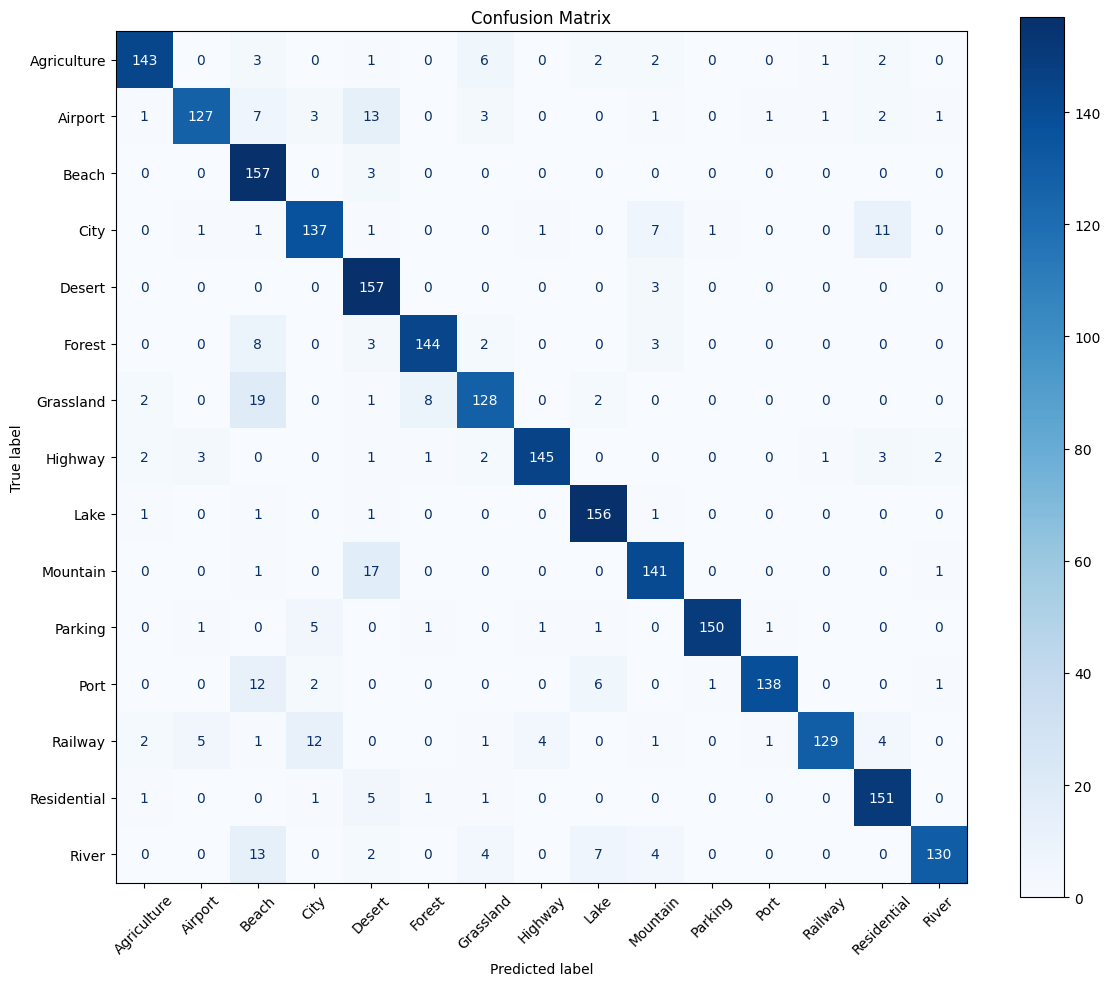

In [10]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [11]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_noise)

# Classification Report
print("\nClassification Report:")
noise_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.910     0.887     0.899       160
     Airport      0.817     0.894     0.854       160
       Beach      0.974     0.706     0.819       160
        City      0.880     0.912     0.896       160
      Desert      0.841     0.431     0.570       160
      Forest      0.497     1.000     0.664       160
   Grassland      0.508     0.825     0.629       160
     Highway      0.974     0.950     0.962       160
        Lake      0.932     0.688     0.791       160
    Mountain      0.744     0.762     0.753       160
     Parking      0.881     0.969     0.923       160
        Port      0.986     0.856     0.916       160
     Railway      0.940     0.887     0.913       160
 Residential      1.000     0.762     0.865       160
       River      0.990     0.600     0.747       160

    accuracy                          0.809      2400
   macro avg      0.858     0.809     0.813      2400
we

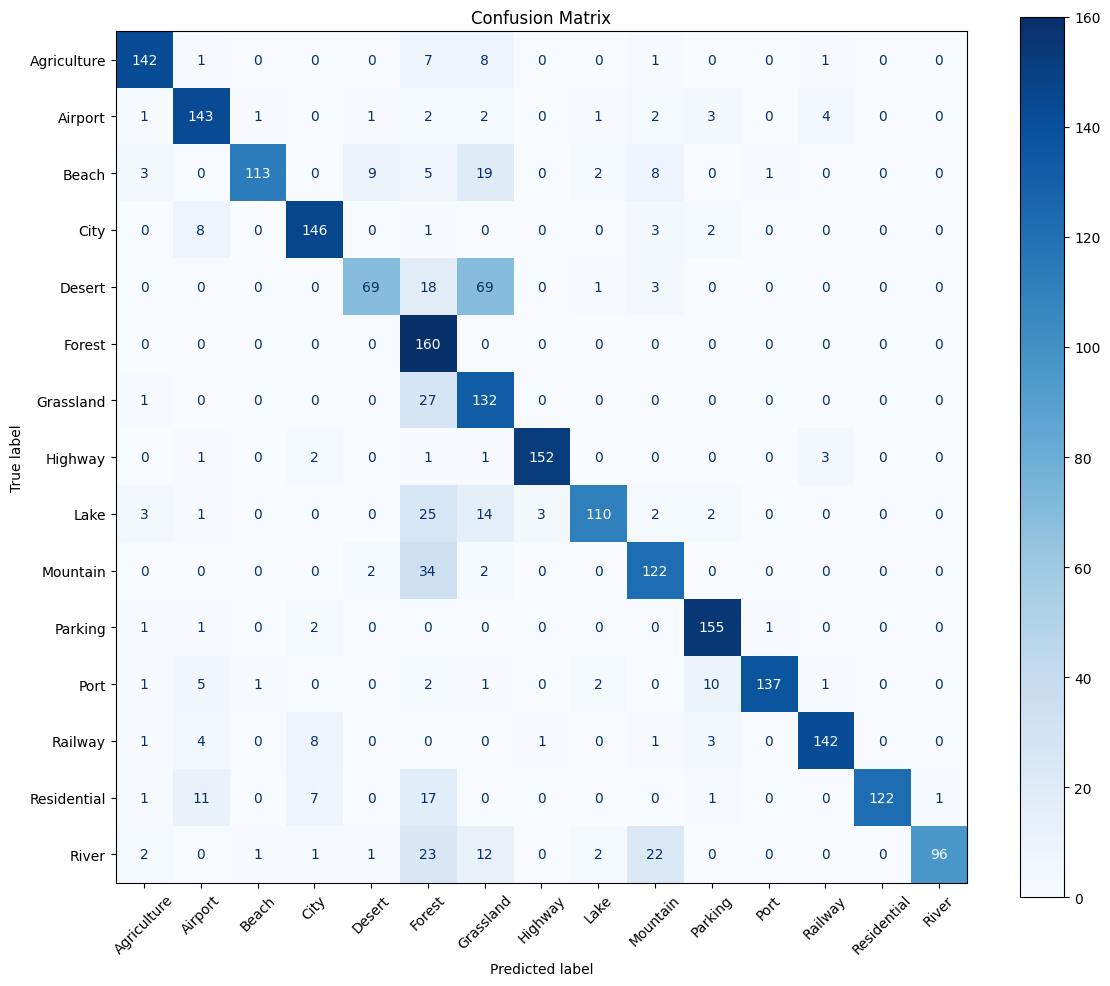

In [12]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

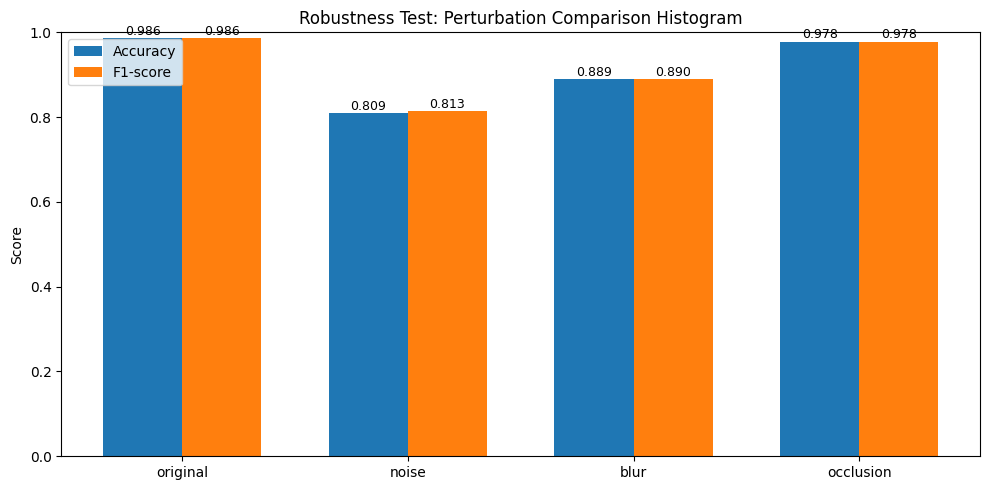

In [13]:
reports = {
    "original": original_classification_report,
    "noise": noise_classification_report,
    "blur": blur_classification_report,
    "occlusion": patch_classification_report
}

# Prepare data
perturbations = ["original", "noise", "blur", "occlusion"]
accuracies = [reports[p]['accuracy'] for p in perturbations]
f1_scores = [reports[p]['macro avg']['f1-score'] for p in perturbations]

# Set bar positions
x = range(len(perturbations))
width = 0.35

# Plot
plt.figure(figsize=(10, 5))
plt.bar([i - width/2 for i in x], accuracies, width=width, label='Accuracy')
plt.bar([i + width/2 for i in x], f1_scores, width=width, label='F1-score')

plt.xticks(ticks=x, labels=perturbations)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Robustness Test: Perturbation Comparison Histogram")
plt.legend()
for i in range(len(perturbations)):
    plt.text(i - width/2, accuracies[i] + 0.001, f"{accuracies[i]:.3f}", ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, f1_scores[i] + 0.001, f"{f1_scores[i]:.3f}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()
